# Pipeline CCCD — Python 3.12.3, giữ model giữa các lần Run trên Colab

Kernel giao diện Colab có thể dùng Python 3.13. Toàn bộ VN-ID, Torch, QR và VietOCR chạy trong một process Python **3.12.3** từ `/content/venv312`.

1. Chạy các cell chuẩn bị môi trường/model theo thứ tự.
2. Chạy mục 6 lần đầu: khởi động process, import, load model và xử lý ảnh đã chọn.
3. Bấm Run lại **riêng cell mục 6**: gửi yêu cầu vào cùng process 3.12.3 và tái sử dụng model.

`total_ms` là thời gian nội bộ pipeline. `pipeline_wall_ms` đo lời gọi pipeline có đồng bộ GPU. `cell_wall_ms` đo toàn bộ yêu cầu, gồm preview, in kết quả và JSON. Không cộng ba số này với nhau.

Process mất khi restart/disconnect runtime. Muốn khởi tạo lại hoặc sau khi sửa mã nguồn, chạy `vnid_worker.terminate(); vnid_worker.wait()` rồi chạy mục 6 lại. Các thư viện OCR không được import vào kernel 3.13.


## 1. Tạo môi trường Python 3.12.3


In [1]:
import os
from pathlib import Path

# Không xóa venv khi chạy lại cell chuẩn bị.
!curl -LsSf https://astral.sh/uv/install.sh | sh
os.environ["PATH"] = "/root/.local/bin:" + os.environ["PATH"]
!uv python install 3.12.3

PY = "/content/venv312/bin/python"
if not Path(PY).exists():
    !uv venv --seed /content/venv312 --python 3.12.3

!{PY} -c "import sys; print(sys.version); assert sys.version_info[:3] == (3, 12, 3)"
!{PY} -m pip --version


downloading uv 0.13.0 x86_64-unknown-linux-gnu
installing to /usr/local/bin
  uv
  uvx
everything's installed!
Installed Python 3.12.3 in 3.50s
 + cpython-3.12.3-linux-x86_64-gnu (python3.12)
Using CPython 3.12.3
Creating virtual environment with seed packages at: venv312
 + pip==26.2.1
Activate with: source venv312/bin/activate
3.12.3 (main, Apr 15 2024, 18:25:56) [Clang 17.0.6 ]
pip 26.2.1 from /content/venv312/lib/python3.12/site-packages/pip (python 3.12)


## 2. Clone VN_ID và cài dependency


In [2]:
import os
import sys

REPO_DIR = "/content/VN_ID"

if not os.path.exists(REPO_DIR):
    !git clone -b test https://github.com/Shinoaki0145/VN_ID.git {REPO_DIR}
else:
    print("Repo đã tồn tại:", REPO_DIR)

# System dependency
!apt-get update -qq
!apt-get install -y -qq libzbar0

PY = "/content/venv312/bin/python"

# Build tools
!{PY} -m pip install -U pip setuptools wheel

# PyTorch + các package OCR/QR
!{PY} -m pip install \
    torch torchvision \
    easyocr \
    qreader \
    zxing-cpp \
    pyzbar \
    einops \
    lmdb \
    gdown \
    prefetch-generator \
    opencv-python-headless \
    matplotlib \
    pillow \
    pyyaml \
    numpy \
    qrdet \
    "pydantic>=2,<3"

# VietOCR
!{PY} -m pip install --no-deps git+https://github.com/pbcquoc/vietocr.git

# Nếu repo có requirements.txt thì cài thêm dependency mà tác giả khai báo
if os.path.exists(os.path.join(REPO_DIR, "requirements.txt")):
    !{PY} -m pip install -r {REPO_DIR}/requirements.txt

print("Cài dependency xong.")


Cloning into '/content/VN_ID'...
remote: Enumerating objects: 316, done.
remote: Counting objects: 100% (316/316), done.
remote: Compressing objects: 100% (233/233), done.
remote: Total 316 (delta 135), reused 258 (delta 80), pack-reused 0 (from 0)
Receiving objects: 100% (316/316), 26.54 MiB | 22.65 MiB/s, done.
Resolving deltas: 100% (135/135), done.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package fonts-droid-fallback.
(Reading database ... 127332 files and directories currently installed.)
Preparing to unpack .../00-fonts-droid-fallback_1%3a6.0.1r16-1.1build1_all.deb ...
Unpacking fonts-droid-fallback (1:6.0.1r16-1.1build1) ...
Selecting previously unselected package liblqr-1-0:amd64.
Preparing to unpack .../01-liblqr-1-0_0.4.2-2.1build2_amd64.deb ...
Unpacking liblqr-1-0:amd64 (0.4.2-2.1build2) ...
Selec

In [3]:
PY = "/content/venv312/bin/python"

# Cài compiler + Ninja cho PyTorch C++/CUDA extensions
!apt-get update -qq
!apt-get install -y build-essential ninja-build

!{PY} -m pip install -U ninja

# Kiểm tra
!{PY} -c "import ninja; print('Ninja:', ninja.__version__)"

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
build-essential is already the newest version (12.10ubuntu1).
The following NEW packages will be installed:
  ninja-build
0 upgraded, 1 newly installed, 0 to remove and 64 not upgraded.
Need to get 129 kB of archives.
After this operation, 364 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 ninja-build amd64 1.11.1-2 [129 kB]
Fetched 129 kB in 1s (174 kB/s)
Selecting previously unselected package ninja-build.
(Reading database ... 128990 files and directories currently installed.)
Preparing to unpack .../ninja-build_1.11.1-2_amd64.deb ...
Unpacking ninja-build (1.11.1-2) ...
Setting up ninja-build (1.11.1-2) ...
Processing triggers for man-db (2.12.0-4

## 3. Kiểm tra Python 3.12.3 và GPU của môi trường pipeline


In [4]:
%%script /content/venv312/bin/python
import sys
import torch
import cv2
import pydantic

assert sys.version_info[:3] == (3, 12, 3), sys.version
print("Python   :", sys.version)
print("Exe      :", sys.executable)
print("Torch    :", torch.__version__)
print("OpenCV   :", cv2.__version__)
print("Pydantic :", pydantic.__version__)
print("CUDA     :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU      :", torch.cuda.get_device_name(0))


Python   : 3.12.3 (main, Apr 15 2024, 18:25:56) [Clang 17.0.6 ]
Exe      : /content/venv312/bin/python
Torch    : 2.14.1+cu130
OpenCV   : 5.0.0
Pydantic : 2.14.0
CUDA     : True
GPU      : Tesla T4


## 4. Ghi script chạy trong process Python 3.12.3 được giữ lại

Cell này chỉ ghi file. Mục 6 gửi yêu cầu chạy script vào cùng process để giữ biến `pipeline` và model giữa các lần Run.


In [5]:
%%writefile /content/run_vnid_pipeline.py
import os
import sys
import json

assert sys.version_info[:3] == (3, 12, 3), sys.version
import time
import torch

# Fix backend Matplotlib khi chạy ngoài kernel Colab
os.environ["MPLBACKEND"] = "Agg"

import cv2
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

REPO_DIR = "/content/VN_ID"
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)
os.chdir(REPO_DIR)

from vn_id import CCCDPipeline, CardSide

FRONT_IMAGE = os.environ.get("FRONT_IMAGE", "").strip()
BACK_IMAGE = os.environ.get("BACK_IMAGE", "").strip()

OUTPUT_DIR = "/content/vnid_output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("=" * 70)
print("Python     :", sys.version)
print("Executable :", sys.executable)
print("Repo       :", REPO_DIR)
print("Front      :", FRONT_IMAGE)
print("Back       :", BACK_IMAGE)
print("=" * 70)


# ------------------------------------------------------------
# Kiểm tra ảnh
# ------------------------------------------------------------
if not FRONT_IMAGE and not BACK_IMAGE:
    raise ValueError("Cần cung cấp ít nhất một ảnh mặt trước hoặc mặt sau.")

# Đọc và tạo preview chỉ cho ảnh được cung cấp trong lượt này.
img_front = None
img_back = None
previews = []
for side_label, image_path in [("Mặt trước", FRONT_IMAGE), ("Mặt sau", BACK_IMAGE)]:
    if not image_path:
        continue
    img = cv2.imread(image_path)
    if img is None:
        raise ValueError(f"OpenCV không đọc được: {image_path}")
    previews.append((img, f"{side_label}: {image_path}"))
    if side_label == "Mặt trước":
        img_front = img
    else:
        img_back = img

preview_file = os.path.join(OUTPUT_DIR, "input_preview.png")
fig, axes = plt.subplots(1, len(previews), figsize=(6 * len(previews), 5), squeeze=False)
for ax, (img, title) in zip(axes[0], previews):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.savefig(preview_file, dpi=150, bbox_inches="tight")
plt.close(fig)

# ------------------------------------------------------------
# Pipeline chính
# ------------------------------------------------------------
# Process 3.12.3 giữ namespace này giữa các yêu cầu.
if "pipeline" not in globals():
    pipeline = CCCDPipeline(device="auto")
    pipeline_run_count = 0

pipeline_run_count = globals().get("pipeline_run_count", 0) + 1
print("Pipeline device:", pipeline.device)
print("Lượt trong process 3.12.3:", pipeline_run_count)
print("Lần đầu có chi phí khởi tạo; các lượt sau tái sử dụng model.")

if pipeline.device.startswith("cuda"):
    torch.cuda.synchronize()
pipeline_start = time.perf_counter()
if FRONT_IMAGE and BACK_IMAGE:
    result = pipeline.process_both_sides(
        front_image=FRONT_IMAGE,
        back_image=BACK_IMAGE,
    )
elif FRONT_IMAGE:
    result = pipeline.process(image=FRONT_IMAGE, force_side=CardSide.FRONT)
else:
    result = pipeline.process(image=BACK_IMAGE, force_side=CardSide.BACK)
if pipeline.device.startswith("cuda"):
    torch.cuda.synchronize()
pipeline_wall_ms = (time.perf_counter() - pipeline_start) * 1000
print(f"pipeline_wall_ms (đồng bộ CUDA nếu có): {pipeline_wall_ms:.2f} ms")

print("\n=== KẾT QUẢ TRÍCH XUẤT THẬT ===")
print("Thành công:", result.success)
print("Mặt phát hiện:", result.side_detected)
print("Nguồn dữ liệu từng trường:", result.field_sources)

print("\n=== ĐO ĐỘ TRỄ (LATENCY BREAKDOWN) ===")
for step, ms in result.timings.items():
    print(f"  * {step:<18}: {ms:8.2f} ms")
print("-" * 36)
print(f"  * TỔNG THỜI GIAN    : {result.timings.get('total_ms', 0):8.2f} ms")

# ------------------------------------------------------------
# Chi tiết dữ liệu
# ------------------------------------------------------------
data = result.data
val = result.validation

print("\n+" + "-"*28 + "+" + "-"*52 + "+")
print(f"| {'TRƯỜNG THÔNG TIN':<26} | {'GIÁ TRỊ':<50} |")
print("+" + "-"*28 + "+" + "-"*52 + "+")

fields = [
    ("Số CCCD", "id"),
    ("Số CMND cũ", "cmnd_old"),
    ("Họ và tên", "name"),
    ("Ngày sinh", "dob"),
    ("Giới tính", "gender"),
    ("Quốc tịch", "nationality"),
    ("Quê quán / Nơi ĐKKS", "origin"),
    ("Nơi thường trú / Cư trú", "residence"),
    ("Ngày cấp", "issue_date"),
    ("Nơi cấp", "issue_loc"),
    ("Có giá trị đến", "expiry_date"),
]

for label, attr in fields:
    value = getattr(data, attr, None)
    print(f"| {label:<26} | {str(value):<50} |")

print("+" + "-"*28 + "+" + "-"*52 + "+")

print("\nĐối soát CCCD:")
print("12 số    :", getattr(val, "is_valid_12_digits", None))
print("Tỉnh     :", getattr(val, "province_valid", None))
print("Năm sinh :", getattr(val, "birth_year_valid", None))

# ------------------------------------------------------------
# Xuất JSON
# ------------------------------------------------------------
output_file = os.path.join(OUTPUT_DIR, "output_result.json")

if hasattr(result, "model_dump"):
    payload = result.model_dump()
elif hasattr(result, "dict"):
    payload = result.dict()
else:
    raise TypeError("Không thể serialize result sang JSON")

with open(output_file, "w", encoding="utf-8") as f:
    json.dump(payload, f, ensure_ascii=False, indent=2, default=str)

print("\n=== HOÀN TẤT ===")
print("JSON   :", output_file)
print("Preview:", preview_file)


Writing /content/run_vnid_pipeline.py


In [6]:
# ============================================================
# PATCH EASYOCR DBNET CUDA CHO PYTORCH MỚI
# ============================================================

from pathlib import Path
import subprocess
import shutil

# Hỏi Python 3.12.3 vị trí easyocr, không import package vào kernel 3.13.
PY = "/content/venv312/bin/python"
easyocr_origin = subprocess.check_output(
    [PY, "-c", "import importlib.util; print(importlib.util.find_spec('easyocr').origin)"],
    text=True,
).strip()
DCN_DIR = Path(easyocr_origin).parent / "DBNet/assets/ops/dcn/src"

files = [
    DCN_DIR / "deform_conv_cuda_kernel.cu",
    DCN_DIR / "deform_pool_cuda_kernel.cu",
]

for file in files:
    print(f"\nPatching: {file}")

    # backup
    backup = Path(str(file) + ".bak")
    if not backup.exists():
        shutil.copy2(file, backup)

    text = file.read_text()

    before = text.count(".type()")

    # PyTorch cũ:
    # tensor.type()
    #
    # PyTorch mới:
    # tensor.scalar_type()
    text = text.replace(".type()", ".scalar_type()")

    file.write_text(text)

    after = text.count(".type()")

    print("  .type() trước patch :", before)
    print("  .type() sau patch   :", after)

print("\nPatch hoàn tất.")


Patching: /content/venv312/lib/python3.12/site-packages/easyocr/DBNet/assets/ops/dcn/src/deform_conv_cuda_kernel.cu
  .type() trước patch : 6
  .type() sau patch   : 0

Patching: /content/venv312/lib/python3.12/site-packages/easyocr/DBNet/assets/ops/dcn/src/deform_pool_cuda_kernel.cu
  .type() trước patch : 2
  .type() sau patch   : 0

Patch hoàn tất.


In [7]:
# Kiểm tra patch trong package của kernel hiện tại.
for file in files:
    remaining = file.read_text().count(".type()")
    print(file.name, "số .type() còn lại:", remaining)
    assert remaining == 0


deform_conv_cuda_kernel.cu số .type() còn lại: 0
deform_pool_cuda_kernel.cu số .type() còn lại: 0


In [8]:
PY = "/content/venv312/bin/python"

!{PY} -m pip install -U ninja
!{PY} -c "import ninja; print('Ninja:', ninja.__version__)"

Ninja: 1.13.2


In [9]:
from pathlib import Path

yaml_path = Path("/content/VN_ID/vn_id/ocr/vgg_seq2seq.yml")

text = yaml_path.read_text(encoding="utf-8")

text = text.replace(
    "weights: /home/thiennhan/IDX/CCCD/VN_ID/.easyocr_models/model/vgg_seq2seq.pth",
    "weights: /content/VN_ID/.easyocr_models/model/vgg_seq2seq.pth"
)

yaml_path.write_text(text, encoding="utf-8")

print(yaml_path.read_text(encoding="utf-8"))

aug:
  image_aug: true
  masked_language_model: true
backbone: vgg19_bn
cnn:
  hidden: 256
  ks:
  - - 2
    - 2
  - - 2
    - 2
  - - 2
    - 1
  - - 2
    - 1
  - - 1
    - 1
  ss:
  - - 2
    - 2
  - - 2
    - 2
  - - 2
    - 1
  - - 2
    - 1
  - - 1
    - 1
dataloader:
  num_workers: 3
  pin_memory: true
dataset:
  data_root: ./img/
  image_height: 32
  image_max_width: 512
  image_min_width: 32
  name: data
  train_annotation: annotation_train.txt
  valid_annotation: annotation_val_small.txt
device: cuda:0
optimizer:
  max_lr: 0.001
  pct_start: 0.1
predictor:
  beamsearch: false
pretrain: https://vocr.vn/data/vietocr/vgg_seq2seq.pth
quiet: false
seq_modeling: seq2seq
trainer:
  batch_size: 32
  checkpoint: ./checkpoint/transformerocr_checkpoint.pth
  export: ./weights/transformerocr.pth
  iters: 100000
  log: ./train.log
  metrics: null
  print_every: 200
  valid_every: 4000
transformer:
  decoder_embedded: 256
  decoder_hidden: 256
  dropout: 0.1
  encoder_hidden: 256
  img_cha

In [10]:
!mkdir -p /content/VN_ID/.easyocr_models/model

In [11]:
!wget -O /content/VN_ID/.easyocr_models/model/vgg_seq2seq.pth \
https://vocr.vn/data/vietocr/vgg_seq2seq.pth

--2026-10-10 03:55:49--  https://vocr.vn/data/vietocr/vgg_seq2seq.pth
Resolving vocr.vn (vocr.vn)... 128.199.222.116
Connecting to vocr.vn (vocr.vn)|128.199.222.116|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 89575371 (85M) [application/octet-stream]
Saving to: ‘/content/VN_ID/.easyocr_models/model/vgg_seq2seq.pth’

/content/VN_ID/.eas 100%[===================>]  85.42M  16.9MB/s    in 6.6s    

2026-10-10 03:55:56 (13.0 MB/s) - ‘/content/VN_ID/.easyocr_models/model/vgg_seq2seq.pth’ saved [89575371/89575371]



In [12]:
!ls -lh /content/VN_ID/.easyocr_models/model/vgg_seq2seq.pth

-rw-r--r-- 1 root root 86M Dec  3  2022 /content/VN_ID/.easyocr_models/model/vgg_seq2seq.pth


## 5. Chọn ảnh đầu vào — mặt trước, mặt sau hoặc cả hai

Upload ảnh vào Files của Colab rồi đặt đường dẫn tương ứng (ví dụ `/content/front.jpg` hoặc `/content/back.jpg`).

- Chỉ mặt trước: `FRONT_IMAGE` có đường dẫn, `BACK_IMAGE = ""`.
- Chỉ mặt sau: `FRONT_IMAGE = ""`, `BACK_IMAGE` có đường dẫn.
- Cả hai mặt: điền cả hai đường dẫn.
- Không có ảnh nào: báo lỗi, không chạy pipeline.

Chạy cell chọn ảnh, cell ghi script mục 5 nếu vừa cập nhật notebook, rồi cell chạy mục 6. Đổi ảnh vẫn dùng cùng process/model Python 3.12.3.


In [50]:
# Điền đường dẫn ảnh; để trống mặt không có.
import os

FRONT_IMAGE = "/content/VN_ID/image/front_cu_7.jpg"
# BACK_IMAGE = ""


# FRONT_IMAGE = ""
BACK_IMAGE = "/content/VN_ID/image/back_cu_7.jpg"


# Kiểm tra file tồn tại ngay tại đây, không đợi tới lúc chạy pipeline.
for label, path in (("Front", FRONT_IMAGE), ("Back", BACK_IMAGE)):
    if path and not os.path.isfile(path):
        raise FileNotFoundError(f"{label}: không tìm thấy file '{path}' (đang chạy tại {os.getcwd()})")
if not FRONT_IMAGE and not BACK_IMAGE:
    raise ValueError("Cần điền ít nhất một đường dẫn ảnh mặt trước hoặc mặt sau.")

print("Front:", FRONT_IMAGE or "Không có", "(OK)" if FRONT_IMAGE else "")
print("Back :", BACK_IMAGE or "Không có", "(OK)" if BACK_IMAGE else "")


Front: /content/VN_ID/image/front_cu_7.jpg (OK)
Back : /content/VN_ID/image/back_cu_7.jpg (OK)


## 6. Chạy pipeline Python 3.12.3 — giữ process và model giữa các lần Run

Bấm Run lần đầu để đo khởi tạo. Bấm lại **riêng cell này** để đo lượt tiếp theo khi model đã sẵn sàng. Mỗi lượt chỉ xử lý ảnh đã chọn.

- `total_ms`: thời gian đo nội bộ pipeline.
- `pipeline_wall_ms`: lời gọi pipeline có đồng bộ GPU trước/sau.
- `cell_wall_ms`: toàn bộ yêu cầu, bao gồm các việc ngoài pipeline và truyền output về Colab.

Đổi ảnh ở mục 5 rồi chạy lại cell này. Nếu sửa mã nguồn, dừng process bằng `vnid_worker.terminate(); vnid_worker.wait()` trước khi chạy lại. Nếu Stop/interrupt cell đang chạy, cell sẽ dừng process để tránh đọc nhầm kết quả ở lượt sau.


In [51]:
import json
import subprocess
import time
import uuid

cell_start = time.perf_counter()
PY = "/content/venv312/bin/python"

# Kernel Colab chỉ dùng stdlib để gửi yêu cầu; mọi OCR/QR chạy trong PY.
worker_code = r"""
import json
import os
import sys
import traceback
from pathlib import Path

assert sys.version_info[:3] == (3, 12, 3), sys.version
scope = {"__name__": "__main__"}
for line in sys.stdin:
    request = json.loads(line)
    ok = False
    try:
        os.environ.update(request["env"])
        script = Path(request["script"])
        scope["__file__"] = str(script)
        exec(compile(script.read_text(encoding="utf-8"), str(script), "exec"), scope)
        ok = True
    except BaseException:
        traceback.print_exc()
    finally:
        print("\n" + request["token"] + json.dumps({"ok": ok}), flush=True)
"""

if "vnid_worker" not in globals() or vnid_worker.poll() is not None:
    vnid_worker = subprocess.Popen(
        [PY, "-u", "-c", worker_code],
        stdin=subprocess.PIPE,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )
    print("Đã tạo process Python 3.12.3, PID:", vnid_worker.pid)
else:
    print("Dùng lại process Python 3.12.3, PID:", vnid_worker.pid)

token = "VNID_DONE_" + uuid.uuid4().hex + ":"
request = {
    "script": "/content/run_vnid_pipeline.py",
    "env": {"FRONT_IMAGE": FRONT_IMAGE or "", "BACK_IMAGE": BACK_IMAGE or "", "MPLBACKEND": "Agg"},
    "token": token,
}
try:
    vnid_worker.stdin.write(json.dumps(request) + "\n")
    vnid_worker.stdin.flush()
    for line in vnid_worker.stdout:
        if line.startswith(token):
            response = json.loads(line[len(token):])
            if not response["ok"]:
                raise RuntimeError("Pipeline bị lỗi; xem traceback phía trên.")
            break
        print(line, end="", flush=True)
    else:
        raise RuntimeError("Process Python 3.12.3 đã kết thúc trước khi trả kết quả.")
except KeyboardInterrupt:
    vnid_worker.terminate()
    vnid_worker.wait()
    raise

cell_wall_ms = (time.perf_counter() - cell_start) * 1000
print(f"\ncell_wall_ms (toàn bộ yêu cầu): {cell_wall_ms:.2f} ms")


Dùng lại process Python 3.12.3, PID: 6017
Python     : 3.12.3 (main, Apr 15 2024, 18:25:56) [Clang 17.0.6 ]
Executable : /content/venv312/bin/python
Repo       : /content/VN_ID
Front      : /content/VN_ID/image/front_cu_7.jpg
Back       : /content/VN_ID/image/back_cu_7.jpg
Pipeline device: cuda
Lượt trong process 3.12.3: 11
Lần đầu có chi phí khởi tạo; các lượt sau tái sử dụng model.
pipeline_wall_ms (đồng bộ CUDA nếu có): 3571.30 ms

=== KẾT QUẢ TRÍCH XUẤT THẬT ===
Thành công: True
Mặt phát hiện: ['front', 'back']
Nguồn dữ liệu từng trường: {'id': 'qr', 'cmnd_old': 'qr', 'name': 'qr', 'dob': 'qr', 'gender': 'qr', 'nationality': 'default', 'origin': 'front_rules', 'residence': 'qr', 'issue_date': 'back_rules', 'issue_loc': 'back_rules', 'expiry_date': 'front_rules'}

=== ĐO ĐỘ TRỄ (LATENCY BREAKDOWN) ===
  * front_align_ms    :    13.65 ms
  * qr_ms             :   172.27 ms
  * front_ocr_det_ms  :   472.08 ms
  * front_ocr_rec_ms  :   834.64 ms
  * front_ocr_sort_ms :     0.32 ms
  * 

## 7. Xem ảnh đầu vào đã render


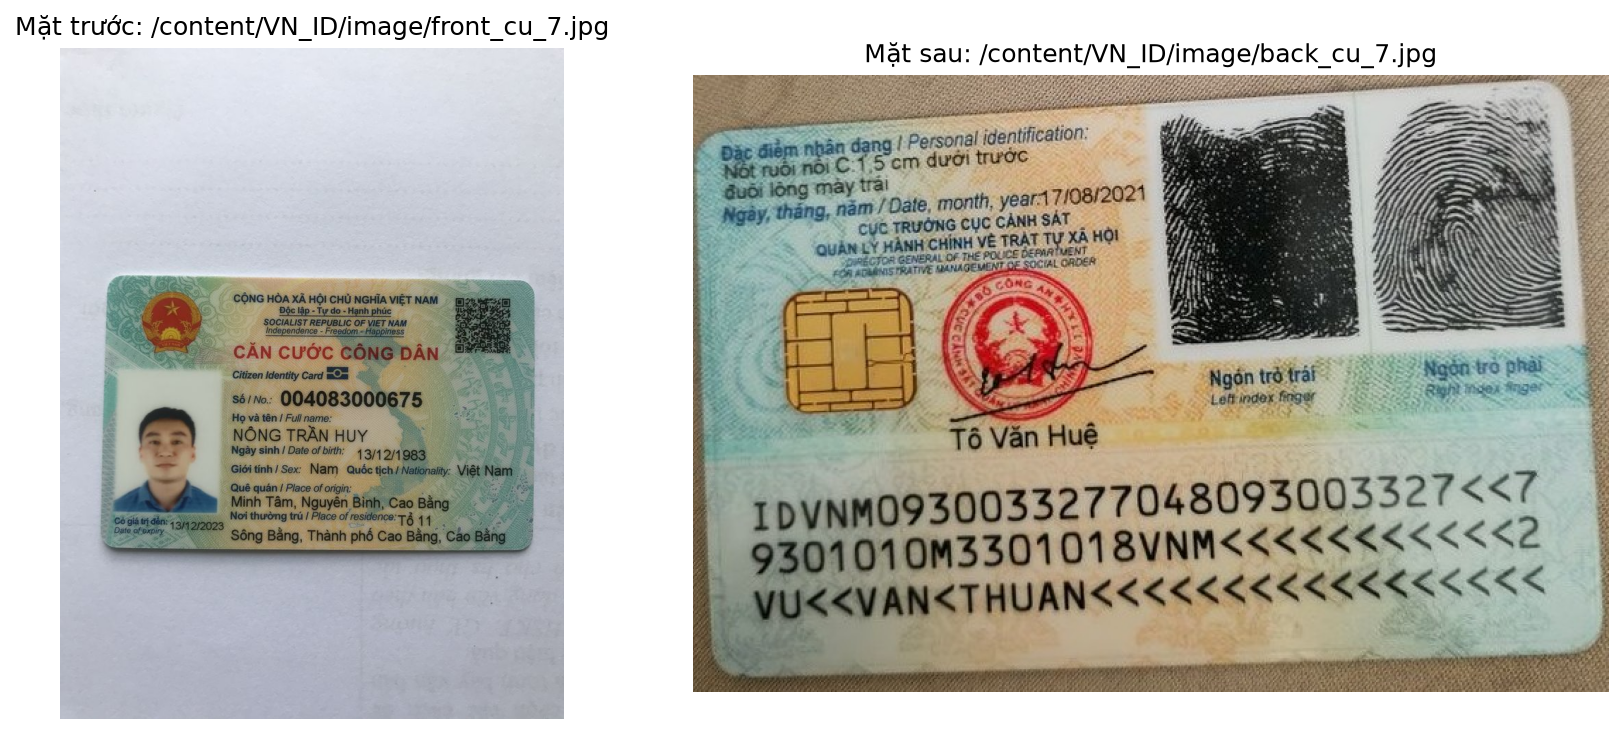

In [52]:
from IPython.display import Image, display
import os

preview = "/content/vnid_output/input_preview.png"

if os.path.exists(preview):
    display(Image(filename=preview))
else:
    print("Chưa có preview. Hãy chạy cell ở mục 6 trước.")


## 8. Xem JSON kết quả


In [53]:
import json
import os

json_path = "/content/vnid_output/output_result.json"

if os.path.exists(json_path):
    with open(json_path, "r", encoding="utf-8") as f:
        result_json = json.load(f)
    print(json.dumps(result_json, ensure_ascii=False, indent=2))
else:
    print("Chưa có JSON. Hãy chạy cell ở mục 6 trước.")


{
  "success": true,
  "side_detected": [
    "front",
    "back"
  ],
  "data": {
    "id": "004083000675",
    "cmnd_old": "080450297",
    "name": "Nông Trần Huy",
    "dob": "13/12/1983",
    "gender": "Nam",
    "nationality": "Việt Nam",
    "origin": "Minh Tâm, Nguyên Bình, Cao Bằng",
    "residence": "Tổ 11, Sông Bằng, Thành phố Cao Bằng, Cao Bằng",
    "issue_date": "17/08/2021",
    "expiry_date": "13/12/2023",
    "issue_loc": "Cục Cảnh sát Quản lý hành chính về trật tự xã hội",
    "father_name": null,
    "mother_name": null
  },
  "field_sources": {
    "id": "qr",
    "cmnd_old": "qr",
    "name": "qr",
    "dob": "qr",
    "gender": "qr",
    "nationality": "default",
    "origin": "front_rules",
    "residence": "qr",
    "issue_date": "back_rules",
    "issue_loc": "back_rules",
    "expiry_date": "front_rules"
  },
  "validation": {
    "is_valid_12_digits": true,
    "province_valid": true,
    "gender_century_valid": true,
    "birth_year_valid": true,
    "address